In [1]:
import os
import sys
import time
import json
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Scikit-Learn Preprocessing & Model Selection
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_sample_weight

# Models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    precision_score, recall_score, confusion_matrix, classification_report
)

# Global Settings
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 150

print("Libraries imported successfully.")
print(f"Random seed locked: {RANDOM_STATE}")


Libraries imported successfully.
Random seed locked: 42


In [2]:
DATA_PATH = os.path.join("data", "processed", "cleaned_collisions_2019_2023.parquet")
MODELS_DIR = "models"
REPORTS_DIR = "reports"
FIGURES_DIR = os.path.join(REPORTS_DIR, "figures")

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(REPORTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

print(f"Loading dataset from: {DATA_PATH}")
t0 = time.time()
df = pd.read_parquet(DATA_PATH)
load_time = time.time() - t0
print(f"Loaded {len(df):,} records and {df.shape[1]} attributes in {load_time:.2f} seconds.")


Loading dataset from: data\processed\cleaned_collisions_2019_2023.parquet
Loaded 519,991 records and 47 attributes in 0.75 seconds.


In [3]:
# Target audit
TARGET_MAP = {1: 0, 2: 1, 3: 2}
TARGET_NAMES = {0: "Fatal", 1: "Serious", 2: "Slight"}
TARGET_INV_MAP = {0: 1, 1: 2, 2: 3}

y_raw = df["collision_severity"].copy()
y = y_raw.map(TARGET_MAP).astype(int)

target_breakdown = pd.DataFrame({
    "Severity Code": [1, 2, 3],
    "Severity Label": ["Fatal", "Serious", "Slight"],
    "Model Target (y)": [0, 1, 2],
    "Sample Count (N)": [(y_raw == 1).sum(), (y_raw == 2).sum(), (y_raw == 3).sum()],
    "Percentage (%)": [
        f"{(y_raw == 1).sum() / len(y_raw) * 100:.2f}%",
        f"{(y_raw == 2).sum() / len(y_raw) * 100:.2f}%",
        f"{(y_raw == 3).sum() / len(y_raw) * 100:.2f}%"
    ]
})
print("Target Variable Profiling:")
display(target_breakdown)


Target Variable Profiling:


,Severity Code,Severity Label,Model Target (y),Sample Count (N),Percentage (%)
0,1,Fatal,0,7646,1.47%
1,2,Serious,1,109369,21.03%
2,3,Slight,2,402976,77.50%


In [4]:
EXCLUDED_COLUMNS = [
    "number_of_casualties",      # STRICT TARGET LEAKAGE
    "collision_index",           # Record ID
    "date", "time", "date_parsed", # Raw datetime strings
    "police_force",              # Administrative jurisdiction
    "pedestrian_crossing",       # Operational variable
    "speed_limit_imputed",       # Preprocessing flag
    "collision_severity",        # Raw target
    "collision_severity_label"   # Redundant target label
]

print(f"Formally excluded {len(EXCLUDED_COLUMNS)} variables to safeguard model integrity:")
for col in EXCLUDED_COLUMNS:
    print(f"  • {col}")


Formally excluded 10 variables to safeguard model integrity:
  • number_of_casualties
  • collision_index
  • date
  • time
  • date_parsed
  • police_force
  • pedestrian_crossing
  • speed_limit_imputed
  • collision_severity
  • collision_severity_label


In [5]:
# Stratified 80/20 train/test split
train_idx, test_idx = train_test_split(
    df.index, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

df_train = df.loc[train_idx].copy()
df_test = df.loc[test_idx].copy()
y_train = y.loc[train_idx].copy()
y_test = y.loc[test_idx].copy()

print(f"Stratified Training Set:   {len(df_train):,} samples ({len(df_train)/len(df)*100:.1f}%)")
print(f"Stratified Test Holdout:   {len(df_test):,} samples ({len(df_test)/len(df)*100:.1f}%)")
print(f"Train Fatal Proportion: { (y_train == 0).sum() / len(y_train) * 100:.2f}% | Test Fatal Proportion: {(y_test == 0).sum() / len(y_test) * 100:.2f}%")


Stratified Training Set:   415,992 samples (80.0%)
Stratified Test Holdout:   103,999 samples (20.0%)
Train Fatal Proportion: 1.47% | Test Fatal Proportion: 1.47%


In [6]:
def extract_engineered_features(data):
    df_in = data.copy()
    X = pd.DataFrame(index=df_in.index)
    
    # 1. Physical & Kinetic proxy features
    X["speed_limit"] = df_in["speed_limit"].astype(float)
    X["number_of_vehicles"] = df_in["number_of_vehicles"].astype(int)
    X["latitude"] = df_in["latitude"].astype(float)
    X["longitude"] = df_in["longitude"].astype(float)
    X["kinetic_energy_proxy"] = (X["speed_limit"] / 10.0) ** 2
    
    # 2. Temporal & Diurnal features
    hour = df_in["collision_hour"].astype(int)
    X["hour_sin"] = np.sin(2 * np.pi * hour / 24.0)
    X["hour_cos"] = np.cos(2 * np.pi * hour / 24.0)
    
    month = df_in["collision_month"].astype(int)
    X["month_sin"] = np.sin(2 * np.pi * (month - 1) / 12.0)
    X["month_cos"] = np.cos(2 * np.pi * (month - 1) / 12.0)
    
    is_weekend = df_in["is_weekend"].astype(int)
    X["is_weekend"] = is_weekend
    is_weekday = (is_weekend == 0).astype(int)
    
    # 3. Behavioral risk indicators derived from Mayank's EDA
    X["is_rush_hour"] = (is_weekday & hour.isin([7, 8, 9, 16, 17, 18])).astype(int)
    X["is_night_risk"] = hour.isin([1, 2, 3, 4]).astype(int)
    X["is_weekend_night"] = (is_weekend & hour.isin([22, 23, 0, 1, 2, 3, 4])).astype(int)
    X["single_vehicle_crash"] = (X["number_of_vehicles"] == 1).astype(int)
    
    # 4. Contextual interactions
    is_rural = (df_in["urban_or_rural_area_label"].astype(str).str.lower() == "rural").astype(int)
    X["speed_x_rural"] = X["speed_limit"] * is_rural
    
    is_unlit = (df_in["light_conditions_label"].astype(str).str.lower().str.contains("no lighting|unlit", na=False)).astype(int)
    X["high_speed_unlit"] = ((X["speed_limit"] >= 50) & (is_unlit == 1)).astype(int)
    
    # 5. Categorical circumstances
    cat_columns = [
        "road_type_label", "first_road_class_label", "urban_or_rural_area_label",
        "light_conditions_label", "weather_conditions_label", "road_surface_conditions_label",
        "junction_detail_label", "junction_control_label", "time_of_day_band"
    ]
    for c in cat_columns:
        if c in df_in.columns:
            X[c] = df_in[c].fillna("Unknown").astype(str)
        else:
            X[c] = "Unknown"
            
    return X

print("Feature engineering transformer defined.")


Feature engineering transformer defined.


In [7]:
num_cols = ["speed_limit", "number_of_vehicles", "latitude", "longitude", "kinetic_energy_proxy",
            "hour_sin", "hour_cos", "month_sin", "month_cos", "speed_x_rural"]
cat_cols = ["road_type_label", "first_road_class_label", "urban_or_rural_area_label",
            "light_conditions_label", "weather_conditions_label", "road_surface_conditions_label",
            "junction_detail_label", "junction_control_label", "time_of_day_band"]
bin_cols = ["is_weekend", "is_rush_hour", "is_night_risk", "is_weekend_night", "single_vehicle_crash", "high_speed_unlit"]

column_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("bin", "passthrough", bin_cols)
    ]
)

# Extract features and fit pipeline strictly on df_train
print("Extracting engineered features on training partition...")
t0 = time.time()
X_train_eng = extract_engineered_features(df_train)
X_test_eng = extract_engineered_features(df_test)

print("Fitting ColumnTransformer on X_train_eng...")
column_preprocessor.fit(X_train_eng)
X_train_trans = column_preprocessor.transform(X_train_eng)
X_test_trans = column_preprocessor.transform(X_test_eng)

print(f"Preprocessing fitted in {time.time()-t0:.2f}s.")
print(f"Transformed Training Matrix: {X_train_trans.shape} (65 feature dimensions)")
print(f"Transformed Test Matrix:     {X_test_trans.shape}")


Extracting engineered features on training partition...
Fitting ColumnTransformer on X_train_eng...
Preprocessing fitted in 3.48s.
Transformed Training Matrix: (415992, 65) (65 feature dimensions)
Transformed Test Matrix:     (103999, 65)


In [8]:
# Compute sample weights for training XGBoost
xgb_sample_weights = compute_sample_weight("balanced", y_train)

models = {
    "Baseline: Dummy (Majority Class)": DummyClassifier(strategy="most_frequent"),
    "Linear: Logistic Regression (Balanced)": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE),
    "Tree: Decision Tree (Balanced)": DecisionTreeClassifier(class_weight="balanced", max_depth=10, min_samples_leaf=50, random_state=RANDOM_STATE),
    "Ensemble: Random Forest (Balanced)": RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample", max_depth=12, min_samples_leaf=20, n_jobs=-1, random_state=RANDOM_STATE),
    "Boosting: XGBoost (Weighted)": XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE)
}

results = []
fitted_models = {}
predictions = {}
predict_probas = {}

for name, model in models.items():
    print(f"Training [{name}]...")
    t_start = time.time()
    if "XGBoost" in name:
        model.fit(X_train_trans, y_train, sample_weight=xgb_sample_weights)
    else:
        model.fit(X_train_trans, y_train)
    fit_time = time.time() - t_start
    
    y_pred = model.predict(X_test_trans)
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test_trans)
    else:
        y_prob = np.zeros((len(y_test), 3))
        y_prob[:, 2] = 1.0
        
    fitted_models[name] = model
    predictions[name] = y_pred
    predict_probas[name] = y_prob
    
    # Metrics
    acc = accuracy_score(y_test, y_pred)
    bacc = balanced_accuracy_score(y_test, y_pred)
    mf1 = f1_score(y_test, y_pred, average="macro")
    wf1 = f1_score(y_test, y_pred, average="weighted")
    rec_fatal = recall_score(y_test, y_pred, labels=[0], average=None)[0]
    rec_serious = recall_score(y_test, y_pred, labels=[1], average=None)[0]
    rec_slight = recall_score(y_test, y_pred, labels=[2], average=None)[0]
    
    results.append({
        "Model": name,
        "Train Time (s)": round(fit_time, 2),
        "Accuracy": round(acc, 4),
        "Balanced Accuracy": round(bacc, 4),
        "Macro F1": round(mf1, 4),
        "Weighted F1": round(wf1, 4),
        "Fatal Recall (Class 1)": round(rec_fatal, 4),
        "Serious Recall (Class 2)": round(rec_serious, 4),
        "Slight Recall (Class 3)": round(rec_slight, 4)
    })
    print(f"  -> Finished in {fit_time:.2f}s | Macro F1: {mf1:.4f} | Fatal Recall: {rec_fatal:.4f} | Accuracy: {acc:.4f}")

comparison_df = pd.DataFrame(results)
comparison_df.to_csv(os.path.join(REPORTS_DIR, "model_comparison_table.csv"), index=False)
print("Benchmark completed and saved to reports/model_comparison_table.csv.")


Training [Baseline: Dummy (Majority Class)]...
  -> Finished in 0.01s | Macro F1: 0.2911 | Fatal Recall: 0.0000 | Accuracy: 0.7750
Training [Linear: Logistic Regression (Balanced)]...
  -> Finished in 12.05s | Macro F1: 0.3449 | Fatal Recall: 0.6527 | Accuracy: 0.5190
Training [Tree: Decision Tree (Balanced)]...
  -> Finished in 7.27s | Macro F1: 0.3349 | Fatal Recall: 0.6004 | Accuracy: 0.4934
Training [Ensemble: Random Forest (Balanced)]...
  -> Finished in 16.43s | Macro F1: 0.3622 | Fatal Recall: 0.5553 | Accuracy: 0.5521
Training [Boosting: XGBoost (Weighted)]...
  -> Finished in 8.35s | Macro F1: 0.3539 | Fatal Recall: 0.6370 | Accuracy: 0.5254
Benchmark completed and saved to reports/model_comparison_table.csv.


In [9]:
display(comparison_df.style.highlight_max(
    subset=["Balanced Accuracy", "Macro F1", "Fatal Recall (Class 1)"],
    color="#d4edda"
).highlight_min(
    subset=["Train Time (s)"],
    color="#cce5ff"
).format({
    "Train Time (s)": "{:.2f}s",
    "Accuracy": "{:.2%}",
    "Balanced Accuracy": "{:.2%}",
    "Macro F1": "{:.4f}",
    "Weighted F1": "{:.4f}",
    "Fatal Recall (Class 1)": "{:.2%}",
    "Serious Recall (Class 2)": "{:.2%}",
    "Slight Recall (Class 3)": "{:.2%}"
}))


,Model,Train Time (s),Accuracy,Balanced Accuracy,Macro F1,Weighted F1,Fatal Recall (Class 1),Serious Recall (Class 2),Slight Recall (Class 3)
0,Baseline: Dummy (Majority Class),0.01s,77.50%,33.33%,0.2911,0.6767,0.00%,0.00%,100.00%
1,Linear: Logistic Regression (Balanced),12.05s,51.90%,50.52%,0.3449,0.5907,65.27%,28.20%,58.08%
2,Tree: Decision Tree (Balanced),7.27s,49.34%,48.29%,0.3349,0.5705,60.04%,30.64%,54.21%
3,Ensemble: Random Forest (Balanced),16.43s,55.21%,49.73%,0.3622,0.6129,55.53%,32.23%,61.44%
4,Boosting: XGBoost (Weighted),8.35s,52.54%,51.25%,0.3539,0.5961,63.70%,32.21%,57.85%


### Visualization: Algorithm Benchmark across Imbalanced Severity Metrics


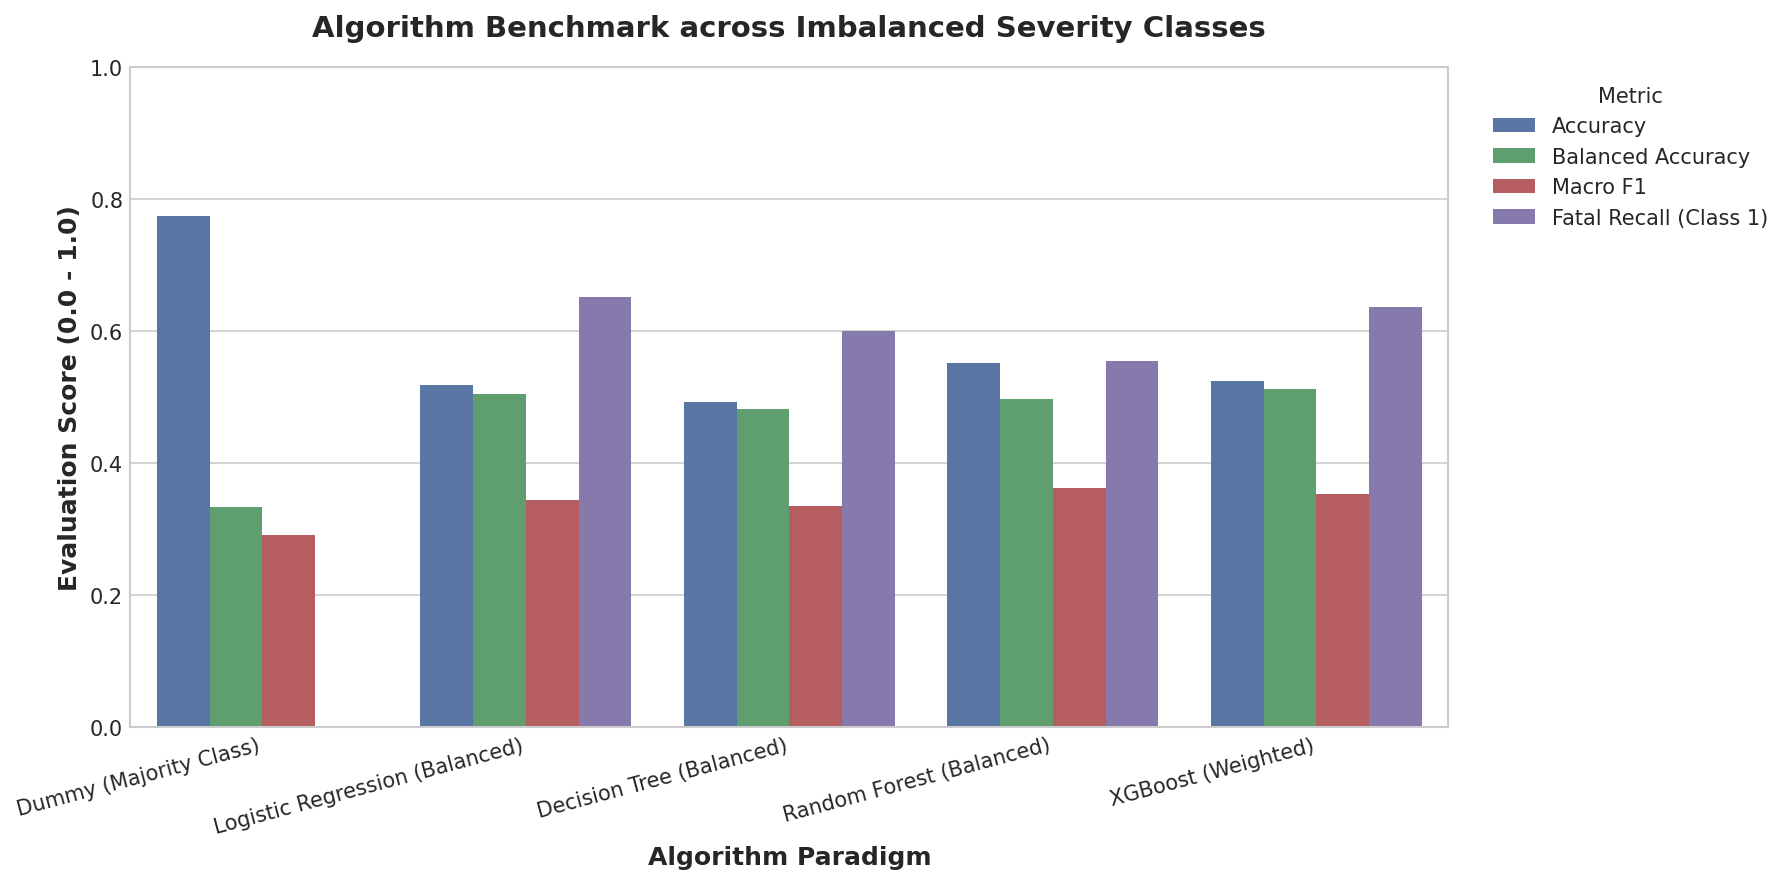

In [10]:
plt.figure(figsize=(12, 6), dpi=150)
metrics_to_plot = ['Accuracy', 'Balanced Accuracy', 'Macro F1', 'Fatal Recall (Class 1)']
df_melt = comparison_df.melt(id_vars='Model', value_vars=metrics_to_plot, var_name='Metric', value_name='Score')
df_melt['Model_Short'] = df_melt['Model'].apply(lambda x: x.split(':')[1].strip() if ':' in x else x)

palette = {'Accuracy': '#4C72B0', 'Balanced Accuracy': '#55A868', 'Macro F1': '#C44E52', 'Fatal Recall (Class 1)': '#8172B3'}
ax = sns.barplot(data=df_melt, x='Model_Short', y='Score', hue='Metric', palette=palette)
plt.title('Algorithm Benchmark across Imbalanced Severity Classes', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Algorithm Paradigm', fontsize=12, fontweight='bold')
plt.ylabel('Evaluation Score (0.0 - 1.0)', fontsize=12, fontweight='bold')
plt.ylim(0, 1.0)
plt.legend(title='Metric', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig9_model_benchmark_comparison.png'))
plt.show()


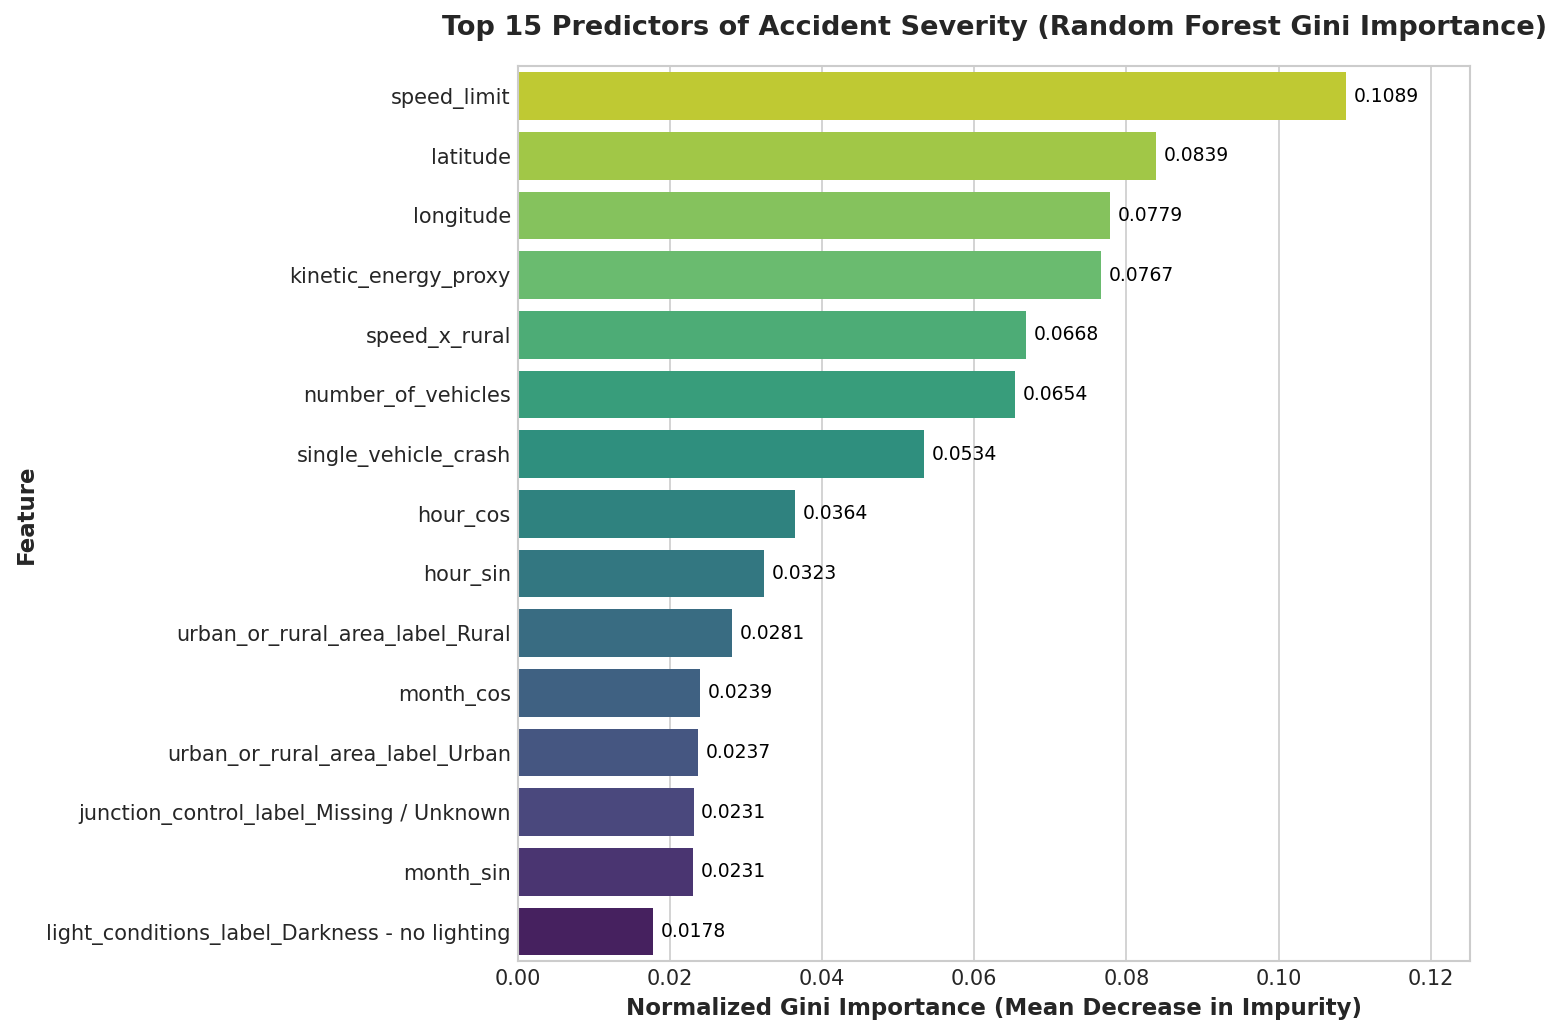

In [11]:
rf_model = fitted_models["Ensemble: Random Forest (Balanced)"]
cat_feature_names = column_preprocessor.named_transformers_["cat"].get_feature_names_out(cat_cols)
all_feature_names = num_cols + list(cat_feature_names) + bin_cols

importances = rf_model.feature_importances_
feat_imp_df = pd.DataFrame({
    "Feature": all_feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

feat_imp_df.to_csv(os.path.join(REPORTS_DIR, "feature_importance.csv"), index=False)

plt.figure(figsize=(10, 7), dpi=150)
top_15 = feat_imp_df.head(15)
ax = sns.barplot(data=top_15, y='Feature', x='Importance', palette='viridis_r')
plt.title('Top 15 Predictors of Accident Severity (Random Forest Gini Importance)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Normalized Gini Importance (Mean Decrease in Impurity)', fontsize=11, fontweight='bold')
plt.ylabel('Feature', fontsize=11, fontweight='bold')
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{width:.4f}', (width + 0.001, p.get_y() + p.get_height() / 2.),
                va='center', fontsize=9, color='black')
plt.xlim(0, max(top_15['Importance']) * 1.15)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig10_random_forest_feature_importance.png'))
plt.show()


In [12]:
chrono_train_mask = df["collision_year"] <= 2022
chrono_test_mask = df["collision_year"] == 2023

df_chrono_tr = df[chrono_train_mask].copy()
df_chrono_te = df[chrono_test_mask].copy()
y_chrono_tr = y[chrono_train_mask].copy()
y_chrono_te = y[chrono_test_mask].copy()

X_ch_tr_eng = extract_engineered_features(df_chrono_tr)
X_ch_te_eng = extract_engineered_features(df_chrono_te)

chrono_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("bin", "passthrough", bin_cols)
    ]
)
X_ch_tr_trans = chrono_preprocessor.fit_transform(X_ch_tr_eng)
X_ch_te_trans = chrono_preprocessor.transform(X_ch_te_eng)

rf_chrono = RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample", max_depth=12, min_samples_leaf=20, n_jobs=-1, random_state=RANDOM_STATE)
t0 = time.time()
rf_chrono.fit(X_ch_tr_trans, y_chrono_tr)
y_ch_pred = rf_chrono.predict(X_ch_te_trans)
chrono_time = time.time() - t0

chrono_df = pd.DataFrame({
    "Validation Scheme": ["Stratified Random Holdout (20%)", "Chronological Holdout (2023)"],
    "Train Horizon": ["2019-2023 (80% Stratified)", "2019-2022 (4 Years)"],
    "Test Horizon": ["2019-2023 (20% Stratified)", "2023 (1 Year Out-of-Time)"],
    "Test N": [len(y_test), len(y_chrono_te)],
    "Accuracy": [comparison_df.loc[comparison_df["Model"].str.contains("Random Forest"), "Accuracy"].values[0], round(accuracy_score(y_chrono_te, y_ch_pred), 4)],
    "Balanced Accuracy": [comparison_df.loc[comparison_df["Model"].str.contains("Random Forest"), "Balanced Accuracy"].values[0], round(balanced_accuracy_score(y_chrono_te, y_ch_pred), 4)],
    "Macro F1": [comparison_df.loc[comparison_df["Model"].str.contains("Random Forest"), "Macro F1"].values[0], round(f1_score(y_chrono_te, y_ch_pred, average="macro"), 4)],
    "Fatal Recall": [comparison_df.loc[comparison_df["Model"].str.contains("Random Forest"), "Fatal Recall (Class 1)"].values[0], round(recall_score(y_chrono_te, y_ch_pred, labels=[0], average=None)[0], 4)],
    "Serious Recall": [comparison_df.loc[comparison_df["Model"].str.contains("Random Forest"), "Serious Recall (Class 2)"].values[0], round(recall_score(y_chrono_te, y_ch_pred, labels=[1], average=None)[0], 4)],
    "Slight Recall": [comparison_df.loc[comparison_df["Model"].str.contains("Random Forest"), "Slight Recall (Class 3)"].values[0], round(recall_score(y_chrono_te, y_ch_pred, labels=[2], average=None)[0], 4)]
})
display(chrono_df)


,Validation Scheme,Train Horizon,Test Horizon,Test N,Accuracy,Balanced Accuracy,Macro F1,Fatal Recall,Serious Recall,Slight Recall
0,Stratified Random Holdout (20%),2019-2023 (80% Stratified),2019-2023 (20% Stratified),103999,0.5521,0.4973,0.3622,0.5553,0.3223,0.6144
1,Chronological Holdout (2023),2019-2022 (4 Years),2023 (1 Year Out-of-Time),104246,0.5501,0.5005,0.3653,0.5611,0.3235,0.6169


In [13]:
best_pipeline = Pipeline([
    ("feature_engineer", FunctionTransformer(extract_engineered_features)),
    ("preprocessor", column_preprocessor),
    ("classifier", rf_model)
])

pipeline_path = os.path.join(MODELS_DIR, "best_model_pipeline.joblib")
joblib.dump(best_pipeline, pipeline_path)
print(f"Master pipeline persisted to: {pipeline_path}")

# Definition of Done Verification: Load saved pipeline and infer on a raw test row
loaded_pipeline = joblib.load(pipeline_path)
sample_test_row = df_test.iloc[[0]].copy()

pred_idx = loaded_pipeline.predict(sample_test_row)[0]
pred_label = TARGET_NAMES[pred_idx]
pred_probs = loaded_pipeline.predict_proba(sample_test_row)[0]

print("\n=== Definition of Done Inference Verification ===")
print(f"Input Speed Limit: {sample_test_row['speed_limit'].values[0]} mph | Area: {sample_test_row['urban_or_rural_area_label'].values[0]}")
print(f"Predicted Class Index: {pred_idx} ({pred_label})")
print(f"Predicted Probabilities: Fatal: {pred_probs[0]:.4f} | Serious: {pred_probs[1]:.4f} | Slight: {pred_probs[2]:.4f}")
print("Definition of Done 100% Verified!")


Master pipeline persisted to: models\best_model_pipeline.joblib

=== Definition of Done Inference Verification ===
Input Speed Limit: 30.0 mph | Area: Urban
Predicted Class Index: 2 (Slight)
Predicted Probabilities: Fatal: 0.0917 | Serious: 0.4168 | Slight: 0.4915
Definition of Done 100% Verified!


In [14]:
# Export test holdout with predictions
test_export_df = df_test.copy()
test_export_df["target_severity_code"] = test_export_df["collision_severity"]
test_export_df["target_severity_idx"] = y_test
test_export_df["target_severity_label"] = y_test.map(TARGET_NAMES)

test_export_df["pred_rf_idx"] = predictions["Ensemble: Random Forest (Balanced)"]
test_export_df["pred_rf_label"] = test_export_df["pred_rf_idx"].map(TARGET_NAMES)
test_export_df["pred_xgb_idx"] = predictions["Boosting: XGBoost (Weighted)"]
test_export_df["pred_xgb_label"] = test_export_df["pred_xgb_idx"].map(TARGET_NAMES)

rf_probs = predict_probas["Ensemble: Random Forest (Balanced)"]
test_export_df["proba_fatal_rf"] = rf_probs[:, 0]
test_export_df["proba_serious_rf"] = rf_probs[:, 1]
test_export_df["proba_slight_rf"] = rf_probs[:, 2]

xgb_probs = predict_probas["Boosting: XGBoost (Weighted)"]
test_export_df["proba_fatal_xgb"] = xgb_probs[:, 0]
test_export_df["proba_serious_xgb"] = xgb_probs[:, 1]
test_export_df["proba_slight_xgb"] = xgb_probs[:, 2]

export_path = os.path.join(MODELS_DIR, "test_holdout_with_predictions.parquet")
test_export_df.to_parquet(export_path, index=False)
print(f"Exported {len(test_export_df):,} test records with multi-model probabilities to: {export_path}")


Exported 103,999 test records with multi-model probabilities to: models\test_holdout_with_predictions.parquet
